**ANOMALY FEATURE**

In [3]:
import digitalhub as dh
import os, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
from sklearn.covariance import ledoit_wolf_shrinkage


PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [24]:
job_name = "net_v5_pool4_pca"

parameters = {
    "job_name": "net_v5_pool4_pca",
    "vectors_from": "net_v5_pool8_vec, net_v5_msPre_pool8_vec, net_v10_pool8_vec_v1, net_v10_ms_v1_pool8_vec_v1",
    "punti": "encoder_fine, pre_proj",
    "k": 1,
    "tagli": "0,1,2,5,10,20,50,100,200,500,1000,2000,4000,8000",
    "max_dim_lw": 8192,
    "shrink_fallback": 0.01,
    "flood_csv_artifact": "flood_pct_Floods_Anomalies_v3",
    "min_flood_anom": 0.0,
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "400Gi"}
    }
]

In [20]:
ocsvm_func = project.new_function(
    name=f'analisi_spettrale',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../../src/",
    handler="anomaly_punti:analisi_spettrale",
    image="harbor.atlas.fbk.eu/rsde/floods-floodsimagev4:68dbc",
)

In [21]:
resources = {"cpu": "4", "mem": "25Gi"}

run_ad = ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection ocsvm: {run_ad.id}")

2026-11-18 15:33:47,784 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0832851c726e405c99783b96bd083156 to finish...


2026-11-18 15:33:52,794 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0832851c726e405c99783b96bd083156 to finish...
2026-11-18 15:33:57,805 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0832851c726e405c99783b96bd083156 to finish...
2026-11-18 15:34:02,816 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0832851c726e405c99783b96bd083156 to finish...
2026-11-18 15:34:07,936 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0832851c726e405c99783b96bd083156 to finish...
2026-11-18 15:34:12,947 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0832851c726e405c99783b96bd083156 to finish...
2026-11-18 15:34:17,960 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0832851c726e405c99783b96bd083156 to finish...
2026-11-18 15:34:22,972 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 0832851c726e405c99783b96bd083156 to finish...
2026-11-18 15

Run anomaly detection ocsvm: 0832851c726e405c99783b96bd083156


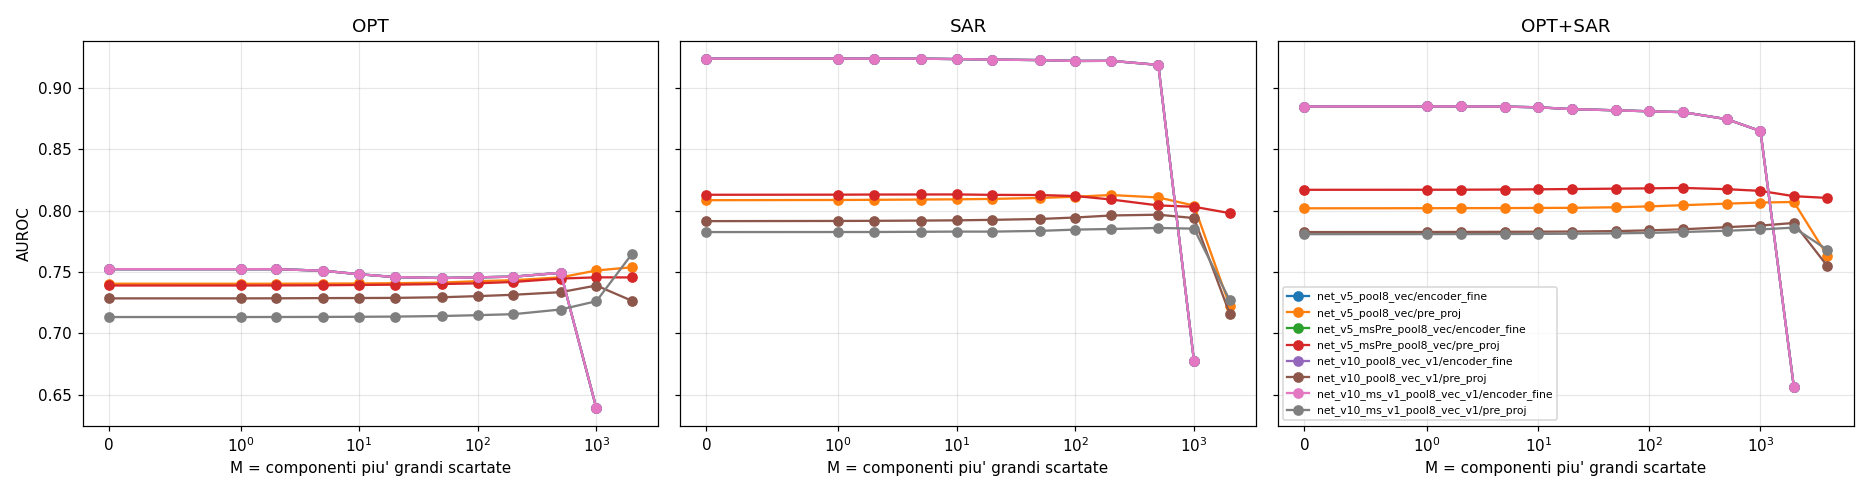

In [25]:
p = project.get_artifact(f"spettrale_{job_name}").download("./spettrale.zip", overwrite=True)
zipfile.ZipFile(p).extractall("./spettrale"); os.remove(p)
tab = pd.read_csv("./spettrale/tabella.csv", index_col=0)

from IPython.display import Image, display
display(Image("./spettrale/minori_confronto.png"))

In [26]:
sezioni = {
    "Dati e componenti": ("serie", "normali", "anomale", "dim ", "componenti", "shrinkage"),
    "PCA del concatenato": ("PCA",),
    "Componenti minori": ("minori",),
    "kNN lw": ("lw",),
}
for titolo, prefissi in sezioni.items():
    righe = [r for r in tab.index if r.startswith(prefissi)]
    if righe:
        print(f"\n===== {titolo} =====")
        display(tab.loc[righe].round(3))


===== Dati e componenti =====


,net_v5_pool8_vec/encoder_fine,net_v5_pool8_vec/pre_proj,net_v5_msPre_pool8_vec/encoder_fine,net_v5_msPre_pool8_vec/pre_proj,net_v10_pool8_vec_v1/encoder_fine,net_v10_pool8_vec_v1/pre_proj,net_v10_ms_v1_pool8_vec_v1/encoder_fine,net_v10_ms_v1_pool8_vec_v1/pre_proj
serie fit,19893.000,19893.000,19893.000,19893.000,19893.000,19893.000,19893.000,19893.000
normali,2402.000,2402.000,2402.000,2402.000,2402.000,2402.000,2402.000,2402.000
anomale,2402.000,2402.000,2402.000,2402.000,2402.000,2402.000,2402.000,2402.000
dim OPT,1024.000,2048.000,1024.000,2048.000,1024.000,2048.000,1024.000,2048.000
dim SAR,1024.000,2048.000,1024.000,2048.000,1024.000,2048.000,1024.000,2048.000
componenti OPT+SAR,2048.000,4096.000,2048.000,4096.000,2048.000,4096.000,2048.000,4096.000
shrinkage OPT+SAR,0.003,0.023,0.003,0.011,0.003,0.027,0.003,0.049
componenti OPT,1024.000,2048.000,1024.000,2048.000,1024.000,2048.000,1024.000,2048.000
shrinkage OPT,0.002,0.011,0.002,0.003,0.002,0.015,0.002,0.018
componenti SAR,1024.000,2048.000,1024.000,2048.000,1024.000,2048.000,1024.000,2048.000



===== PCA del concatenato =====


,net_v5_pool8_vec/encoder_fine,net_v5_pool8_vec/pre_proj,net_v5_msPre_pool8_vec/encoder_fine,net_v5_msPre_pool8_vec/pre_proj,net_v10_pool8_vec_v1/encoder_fine,net_v10_pool8_vec_v1/pre_proj,net_v10_ms_v1_pool8_vec_v1/encoder_fine,net_v10_ms_v1_pool8_vec_v1/pre_proj
PCA AUROC max componente,0.797,0.745,0.797,0.693,0.797,0.745,0.797,0.762
PCA posizione componente migliore,15.000,7.000,15.000,100.000,15.000,15.000,15.000,37.000
PCA posizione mediana top-10,11.500,24.500,11.500,75.000,11.500,20.000,11.500,75.000
PCA AUROC medio primo 10%,0.533,0.548,0.533,0.548,0.533,0.549,0.533,0.543
PCA AUROC medio ultimo 10%,0.509,0.515,0.509,0.514,0.509,0.515,0.509,0.517
PCA quota OTTICO primo 10%,0.473,0.603,0.473,0.459,0.473,0.584,0.473,0.569
PCA quota OTTICO top-10,0.552,0.601,0.552,0.493,0.552,0.548,0.552,0.568



===== Componenti minori =====


,net_v5_pool8_vec/encoder_fine,net_v5_pool8_vec/pre_proj,net_v5_msPre_pool8_vec/encoder_fine,net_v5_msPre_pool8_vec/pre_proj,net_v10_pool8_vec_v1/encoder_fine,net_v10_pool8_vec_v1/pre_proj,net_v10_ms_v1_pool8_vec_v1/encoder_fine,net_v10_ms_v1_pool8_vec_v1/pre_proj
minori OPT AUROC M=0,0.752,0.740,0.752,0.739,0.752,0.729,0.752,0.713
minori OPT M migliore,2.000,2000.000,2.000,1000.000,2.000,1000.000,2.000,2000.000
minori OPT AUROC M migliore,0.752,0.754,0.752,0.746,0.752,0.739,0.752,0.765
minori SAR AUROC M=0,0.924,0.808,0.924,0.813,0.924,0.791,0.924,0.782
minori SAR M migliore,1.000,200.000,1.000,10.000,1.000,500.000,1.000,500.000
minori SAR AUROC M migliore,0.924,0.813,0.924,0.813,0.924,0.797,0.924,0.786
minori OPT+SAR AUROC M=0,0.885,0.802,0.885,0.817,0.885,0.782,0.885,0.781
minori OPT+SAR M migliore,2.000,2000.000,2.000,200.000,2.000,2000.000,2.000,2000.000
minori OPT+SAR AUROC M migliore,0.885,0.807,0.885,0.818,0.885,0.790,0.885,0.786



===== kNN lw =====


,net_v5_pool8_vec/encoder_fine,net_v5_pool8_vec/pre_proj,net_v5_msPre_pool8_vec/encoder_fine,net_v5_msPre_pool8_vec/pre_proj,net_v10_pool8_vec_v1/encoder_fine,net_v10_pool8_vec_v1/pre_proj,net_v10_ms_v1_pool8_vec_v1/encoder_fine,net_v10_ms_v1_pool8_vec_v1/pre_proj
lw AUROC completa,0.882,0.803,0.882,0.818,0.882,0.784,0.882,0.782
lw AUROC parte OPT,0.746,0.737,0.746,0.709,0.746,0.731,0.746,0.713
lw AUROC parte SAR,0.915,0.795,0.915,0.809,0.915,0.785,0.915,0.782
lw AUROC parte incrociata,0.497,0.382,0.497,0.477,0.497,0.371,0.497,0.357
lw AUROC solo OPT,0.750,0.744,0.750,0.741,0.750,0.732,0.750,0.716
lw AUROC solo SAR,0.923,0.808,0.923,0.812,0.923,0.791,0.923,0.782
lw AUROC a blocchi,0.878,0.798,0.878,0.810,0.878,0.780,0.878,0.777
lw quota OPT normali,0.426,0.469,0.426,0.507,0.426,0.477,0.426,0.425
lw quota OPT anomale,0.420,0.476,0.420,0.512,0.420,0.469,0.420,0.450
lw quota SAR normali,0.627,0.602,0.627,0.616,0.627,0.572,0.627,0.614


In [5]:
VERSIONI = ["net_v5_0per", "net_v5_msPre_ep10", "net_v5_msPre_pool8_vec", "net_v5_msPre_pool16_vec"]
PUNTO = "encoder_fine"
CANALI = {"encoder": 16, "encoder_fine": 16, "pre_proj": 128, "pre_proj_fine": 128, "pre_proj_ms": 128}

CARTELLA = "./vec"          

In [3]:
# download embedding da digitalhub

for ver in VERSIONI:
    dest = f"{CARTELLA}/{ver}/{PUNTO}/embeddings.npz"
    if os.path.exists(dest):
        print(f"{ver}: già presente"); continue
    os.makedirs(CARTELLA, exist_ok=True)
    p = project.get_artifact(f"anomaly_results_ocsvm_{ver}").download(f"{CARTELLA}/_tmp_{ver}.zip", overwrite=True)
    with zipfile.ZipFile(p) as z:
        membri = [f"{PUNTO}/embeddings.npz", "summary.json"]
        for m in membri:
            if m in z.namelist():
                z.extract(m, f"{CARTELLA}/{ver}")
        ok = f"{PUNTO}/embeddings.npz" in z.namelist()
    os.remove(p)
    print(f"{ver}: {'OK' if ok else 'PUNTO NON PRESENTE'}")

NameError: name 'os' is not defined

In [5]:
# stampa configurazioni trovate per punto

dati = {}
for ver in VERSIONI:
    path = f"{CARTELLA}/{ver}/{PUNTO}/embeddings.npz"
    if not os.path.exists(path):
        print(f"{ver}: manca {PUNTO}, salto"); continue
    E = np.load(path)
    cat = lambda gr: np.concatenate([E[f"{gr}_q"], E[f"{gr}_k"]], axis=1).astype(np.float32)
    Dq, Dk = E["fit_q"].shape[1], E["fit_k"].shape[1]
    C = CANALI[PUNTO]
    g = int(round(np.sqrt(Dq / C)))
    assert C * g * g == Dq, f"{ver}: {Dq} dimensioni non sono {C} canali x griglia quadrata"
    dati[ver] = {"Xf": cat("fit"), "Xn": cat("normal"), "Xa": cat("anom"),
                 "Dq": Dq, "C": C, "g": g,
                 "anom_flood": E["anom_flood"] if "anom_flood" in E.files else None}
    print(f"{ver}: ottico {Dq} + SAR {Dk} = {Dq + Dk} dim | griglia {g}x{g}, {C} canali | "
          f"fit {len(dati[ver]['Xf'])}, normali {len(dati[ver]['Xn'])}, anomale {len(dati[ver]['Xa'])}")

net_v5_0per: manca encoder_fine, salto
net_v5_msPre_ep10: manca encoder_fine, salto
net_v5_msPre_pool8_vec: ottico 1024 + SAR 1024 = 2048 dim | griglia 8x8, 16 canali | fit 19893, normali 2402, anomale 2402
net_v5_msPre_pool16_vec: ottico 4096 + SAR 4096 = 8192 dim | griglia 16x16, 16 canali | fit 19893, normali 2402, anomale 2402


In [ ]:
FLOOD_CSV = None            

if FLOOD_CSV:
    fp = pd.read_csv(FLOOD_CSV, dtype={"ID": str}).set_index("ID")["flood_pct"]
    for ver, d in dati.items():
        ids = [str(i) for i in np.load(f"{CARTELLA}/{ver}/{PUNTO}/embeddings.npz")["anom_ids"]]
        d["anom_flood"] = fp.reindex(ids).values                       # NaN se un ID manca nel CSV

for ver, d in dati.items():
    f = d.get("anom_flood")
    if f is None:
        print(f"{ver}: MANCA la percentuale allagata (anom_flood) -> sezione R saltata per questa versione")
    else:
        f = np.asarray(f, dtype=float)
        print(f"{ver}: {np.isfinite(f).sum()} anomale con percentuale | "
              f"min {np.nanmin(f):.1f}% | mediana {np.nanmedian(f):.1f}% | max {np.nanmax(f):.1f}%")

NameError: name 'dati' is not defined

In [6]:
# funzioni

def descrivi(j, Dq, C, g):
    mod = "OPT" if j < Dq else "SAR"
    c, r = divmod(j % Dq, g * g)
    return mod, c, r // g, r % g



In [7]:
# calcolo auroc

def auroc_colonne(Xn, Xa):
    X = np.r_[Xn, Xa]
    r = rankdata(X, axis=0)                          
    n_n, n_a = len(Xn), len(Xa)
    a = (r[n_n:].sum(0) - n_a * (n_a + 1) / 2) / (n_n * n_a)
    return a, np.maximum(a, 1 - a)                   

for ver, d in dati.items():
    d["auroc_dir"], d["auroc"] = auroc_colonne(d["Xn"], d["Xa"])
    print(f"{ver}: ok")

net_v5_msPre_pool8_vec: ok
net_v5_msPre_pool16_vec: ok


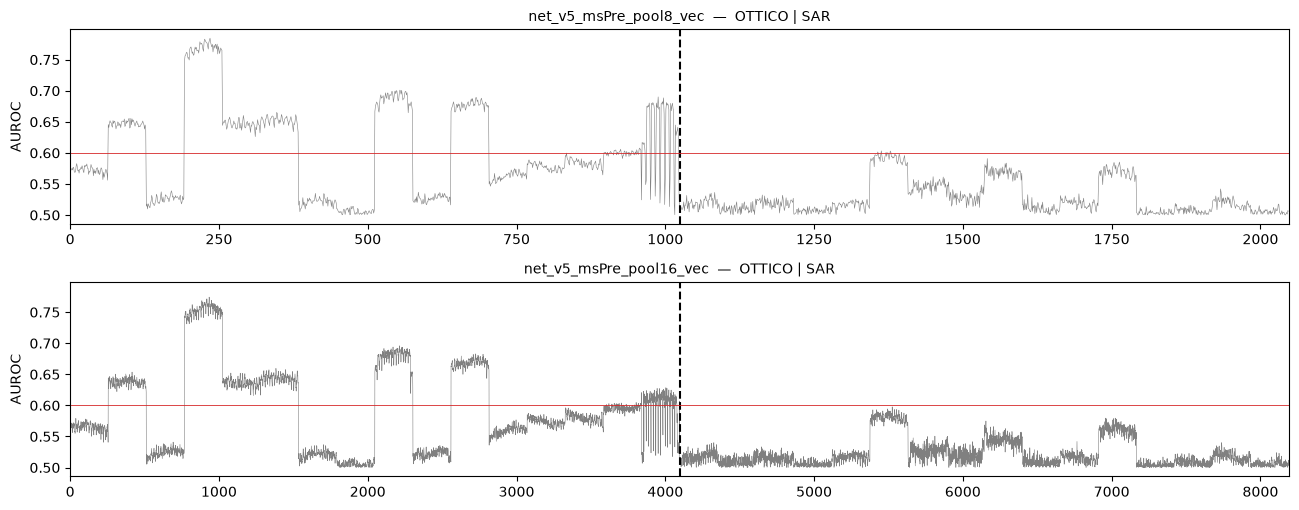

media  mediana    max  n > 0.6  quota > 0.6
net_v5_msPre_pool8_vec  OPT  0.605    0.588  0.785    465.0        0.454
                        SAR  0.528    0.518  0.603      6.0        0.006
net_v5_msPre_pool16_vec OPT  0.597    0.585  0.774   1760.0        0.430
                        SAR  0.522    0.515  0.598      0.0        0.000

In [8]:
# componenti piu significative -> 0.60 = info

fig, axs = plt.subplots(len(dati), 1, figsize=(13, 2.6 * len(dati)), squeeze=False, sharey=True)
for ax, (ver, d) in zip(axs[:, 0], dati.items()):
    ax.plot(d["auroc"], lw=.4, color="gray")
    ax.axvline(d["Dq"], color="k", ls="--")
    ax.axhline(.6, color="tab:red", lw=.6)
    ax.set_xlim(0, len(d["auroc"]))
    ax.set_title(f"{ver}  —  OTTICO | SAR", fontsize=10); ax.set_ylabel("AUROC")
plt.tight_layout(); plt.show()

riassunto = {}
for ver, d in dati.items():
    for mod, a in (("OPT", d["auroc"][:d["Dq"]]), ("SAR", d["auroc"][d["Dq"]:])):
        riassunto[(ver, mod)] = {"media": a.mean(), "mediana": np.median(a), "max": a.max(),
                                 "n > 0.6": int((a > .6).sum()), "quota > 0.6": (a > .6).mean()}
pd.DataFrame(riassunto).T.round(3)

In [9]:
# componenti piu significative -> tab

N_TOP = 10
tabelle = []
for ver, d in dati.items():
    for j in np.argsort(d["auroc"])[::-1][:N_TOP]:
        mod, c, r, col = descrivi(j, d["Dq"], d["C"], d["g"])
        tabelle.append({"versione": ver, "colonna": j, "modalità": mod, "canale": c, "cella": (r, col),
                        "AUROC": d["auroc"][j],
                        "direzione": "anom > norm" if d["auroc_dir"][j] > .5 else "anom < norm"})
top = pd.DataFrame(tabelle)
top.round(3)

,versione,colonna,modalità,canale,cella,AUROC,direzione
0,net_v5_msPre_pool8_vec,235,OPT,3,"(5, 3)",0.785,anom < norm
1,net_v5_msPre_pool8_vec,226,OPT,3,"(4, 2)",0.783,anom < norm
2,net_v5_msPre_pool8_vec,234,OPT,3,"(5, 2)",0.781,anom < norm
3,net_v5_msPre_pool8_vec,227,OPT,3,"(4, 3)",0.781,anom < norm
4,net_v5_msPre_pool8_vec,218,OPT,3,"(3, 2)",0.779,anom < norm
5,net_v5_msPre_pool8_vec,228,OPT,3,"(4, 4)",0.779,anom < norm
6,net_v5_msPre_pool8_vec,225,OPT,3,"(4, 1)",0.778,anom < norm
7,net_v5_msPre_pool8_vec,236,OPT,3,"(5, 4)",0.778,anom < norm
8,net_v5_msPre_pool8_vec,233,OPT,3,"(5, 1)",0.778,anom < norm
9,net_v5_msPre_pool8_vec,229,OPT,3,"(4, 5)",0.778,anom < norm


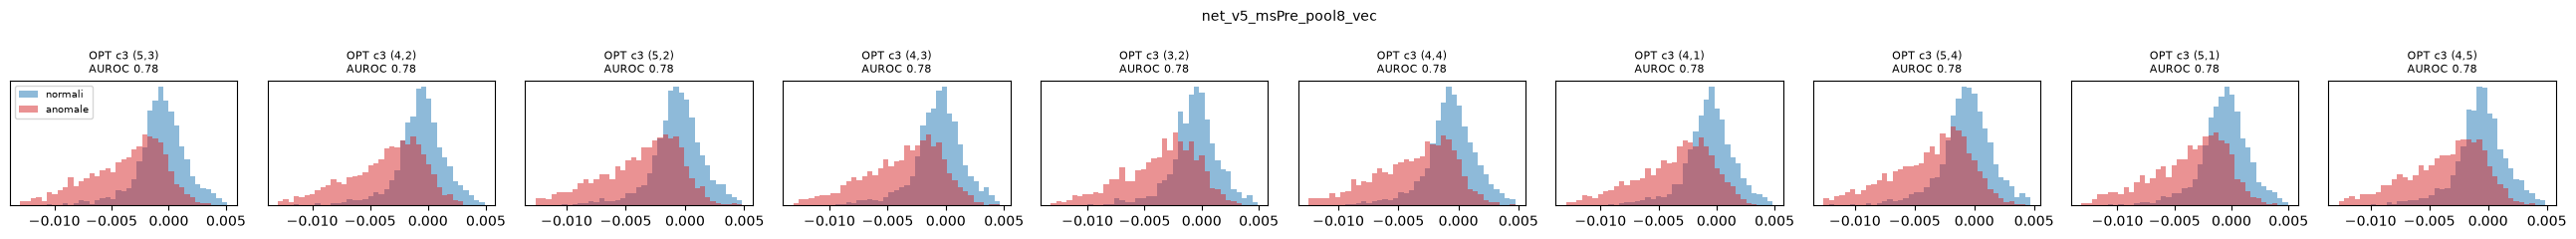

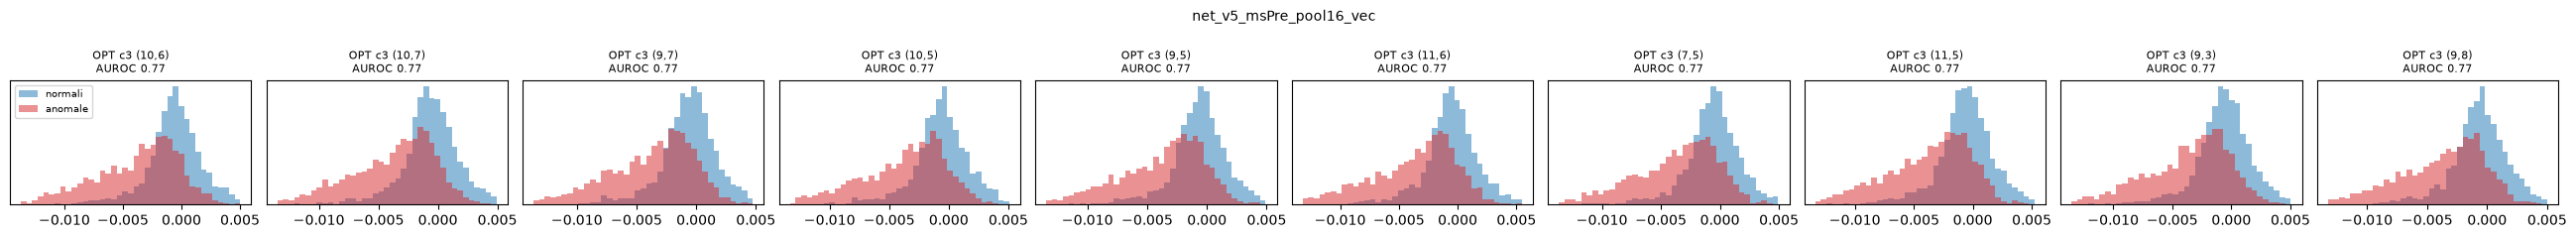

In [10]:
# componenti piu significative -> istogrammi

N_ISTO = 10
for ver, d in dati.items():
    fig, axs = plt.subplots(1, N_ISTO, figsize=(2.6 * N_ISTO, 2.4))
    for ax, j in zip(axs, np.argsort(d["auroc"])[::-1][:N_ISTO]):
        mod, c, r, col = descrivi(j, d["Dq"], d["C"], d["g"])
        bins = np.linspace(*np.percentile(np.r_[d["Xn"][:, j], d["Xa"][:, j]], [0.5, 99.5]), 40)
        ax.hist(d["Xn"][:, j], bins, alpha=.5, density=True, label="normali")
        ax.hist(d["Xa"][:, j], bins, alpha=.5, density=True, label="anomale", color="tab:red")
        ax.set_title(f"{mod} c{c} ({r},{col})\nAUROC {d['auroc'][j]:.2f}", fontsize=8)
        ax.set_yticks([])
    axs[0].legend(fontsize=7); fig.suptitle(ver, fontsize=10)
    plt.tight_layout(); plt.show()

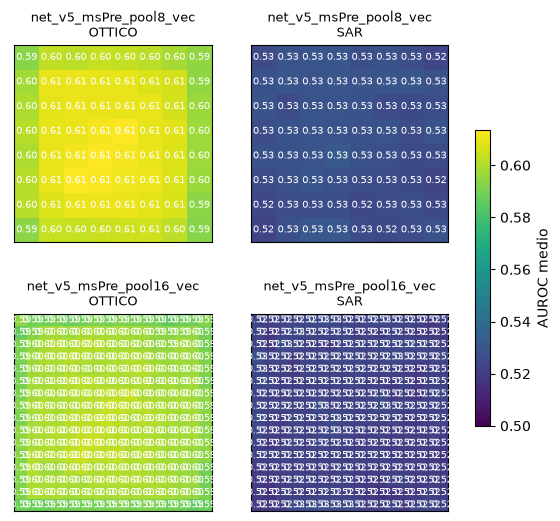

In [11]:
fig, axs = plt.subplots(len(dati), 2, figsize=(7, 3.2 * len(dati)), squeeze=False)
vmax = max(d["auroc"].reshape(2, d["C"], d["g"], d["g"]).mean(1).max() for d in dati.values())
for riga, (ver, d) in zip(axs, dati.items()):
    mappe = d["auroc"].reshape(2, d["C"], d["g"], d["g"]).mean(1)     # (modalità, g, g)
    for ax, m, nome in zip(riga, mappe, ("OTTICO", "SAR")):
        im = ax.imshow(m, vmin=.5, vmax=vmax, cmap="viridis")
        for (i, k), val in np.ndenumerate(m):
            ax.text(k, i, f"{val:.2f}", ha="center", va="center", fontsize=7, color="w")
        ax.set_title(f"{ver}\n{nome}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axs, shrink=.6, label="AUROC medio")
plt.show()

**DIST EUC SAR vs OPT vs CONC**

In [12]:
# calcolo distanza euclidea sar vs ottico vs concatenazione

K = 1
PESI = np.round(np.linspace(0, 1, 11), 2)      
MAX_FIT = 5000
BLOCCO = 500                                   

def knn_pesato(Xt, Xf, Dq, k=K, pesi=PESI, blocco=BLOCCO):
    Fq, Fk = Xf[:, :Dq], Xf[:, Dq:]
    nFq, nFk = (Fq ** 2).sum(1), (Fk ** 2).sum(1)
    score = {w: [] for w in pesi}
    opt, sar = [], []
    for i in range(0, len(Xt), blocco):
        Tq, Tk = Xt[i:i + blocco, :Dq], Xt[i:i + blocco, Dq:]
        d_opt = np.clip((Tq ** 2).sum(1)[:, None] + nFq[None] - 2 * Tq @ Fq.T, 0, None)   
        d_sar = np.clip((Tk ** 2).sum(1)[:, None] + nFk[None] - 2 * Tk @ Fk.T, 0, None)
        for w in pesi:
            d = w * d_opt + (1 - w) * d_sar
            vic = np.argpartition(d, k - 1, axis=1)[:, :k]                                  
            score[w].append(np.take_along_axis(d, vic, 1).mean(1))
            if w == 0.5:                                                                     
                opt.append(np.take_along_axis(d_opt, vic, 1).mean(1))
                sar.append(np.take_along_axis(d_sar, vic, 1).mean(1))
    return {w: np.concatenate(v) for w, v in score.items()}, (np.concatenate(opt), np.concatenate(sar))

def auroc(sn, sa):
    y = np.r_[np.zeros(len(sn)), np.ones(len(sa))]
    from sklearn.metrics import roc_auc_score
    return roc_auc_score(y, np.r_[sn, sa])

rng = np.random.default_rng(0)
for ver, d in dati.items():
    Xf = d["Xf"]
    if MAX_FIT and len(Xf) > MAX_FIT:
        Xf = Xf[rng.choice(len(Xf), MAX_FIT, replace=False)]
    mu, sd = Xf.mean(0), Xf.std(0) + 1e-8                    
    Zf, Zn, Za = (Xf - mu) / sd, (d["Xn"] - mu) / sd, (d["Xa"] - mu) / sd
    d["score_n"], d["parti_n"] = knn_pesato(Zn, Zf, d["Dq"])
    d["score_a"], d["parti_a"] = knn_pesato(Za, Zf, d["Dq"])
    print(f"{ver}: fatto")

net_v5_msPre_pool8_vec: fatto
net_v5_msPre_pool16_vec: fatto


In [13]:
riass1 = {}
for ver, d in dati.items():
    (on, sn), (oa, sa) = d["parti_n"], d["parti_a"]
    curva = {w: auroc(d["score_n"][w], d["score_a"][w]) for w in PESI}
    d["curva_w"] = curva
    w_best = max(curva, key=curva.get)
    riass1[ver] = {
        "AUROC concatenato": curva[0.5],
        "AUROC parte OPT": auroc(on, oa),
        "AUROC parte SAR": auroc(sn, sa),
        "AUROC solo SAR (w=0)": curva[0.0],
        "AUROC solo OPT (w=1)": curva[1.0],
        "quota OPT normali": (on / (on + sn)).mean(),
        "quota OPT anomale": (oa / (oa + sa)).mean(),
        "w migliore": w_best,
        "AUROC con w migliore": curva[w_best],
    }
pd.DataFrame(riass1).round(3)

,net_v5_msPre_pool8_vec,net_v5_msPre_pool16_vec
AUROC concatenato,0.862,0.889
AUROC parte OPT,0.818,0.825
AUROC parte SAR,0.855,0.885
AUROC solo SAR (w=0),0.864,0.906
AUROC solo OPT (w=1),0.821,0.826
quota OPT normali,0.412,0.387
quota OPT anomale,0.435,0.420
w migliore,0.200,0.100
AUROC con w migliore,0.869,0.906


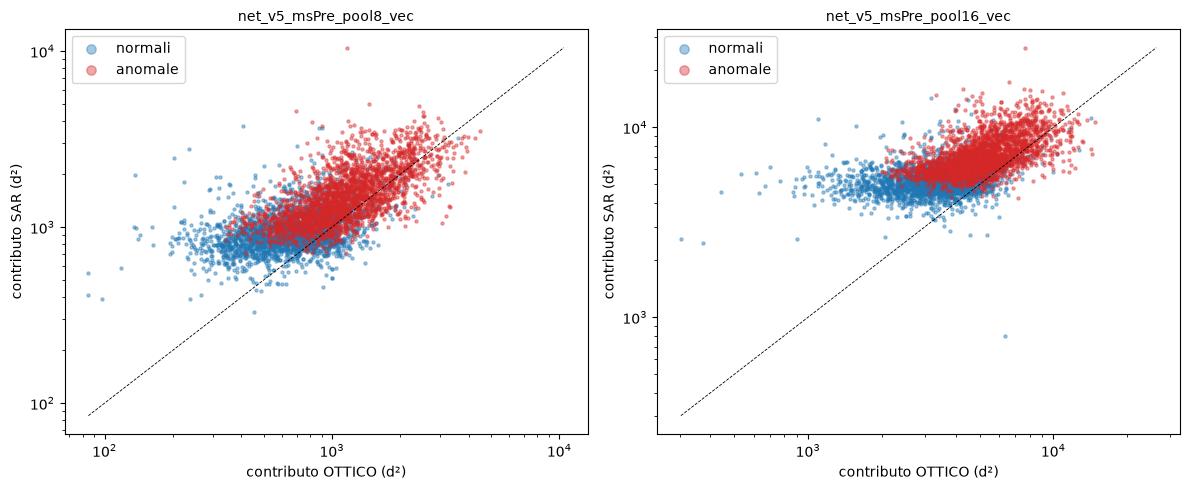

In [14]:
# è piu vicina la ka per ottico o sar

fig, axs = plt.subplots(1, len(dati), figsize=(6 * len(dati), 5), squeeze=False)
for ax, (ver, d) in zip(axs[0], dati.items()):
    (on, sn), (oa, sa) = d["parti_n"], d["parti_a"]
    ax.scatter(on, sn, s=5, alpha=.4, label="normali")
    ax.scatter(oa, sa, s=5, alpha=.4, label="anomale", color="tab:red")
    lim = [min(on.min(), sn.min(), oa.min(), sa.min()), max(on.max(), sn.max(), oa.max(), sa.max())]
    ax.plot(lim, lim, "k--", lw=.6)                          # sopra la diagonale: pesa più il SAR
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("contributo OTTICO (d²)"); ax.set_ylabel("contributo SAR (d²)")
    ax.set_title(ver, fontsize=10); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

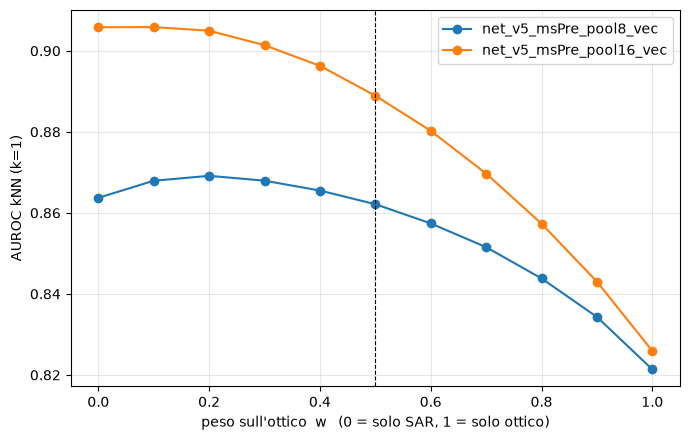

In [15]:
# auroc migliore a parità di percentuale di sar e ottico

fig, ax = plt.subplots(figsize=(7, 4.5))
for ver, d in dati.items():
    c = d["curva_w"]
    ax.plot(list(c), list(c.values()), marker="o", label=ver)
ax.axvline(.5, color="k", ls="--", lw=.8)
ax.set_xlabel("peso sull'ottico  w   (0 = solo SAR, 1 = solo ottico)")
ax.set_ylabel(f"AUROC kNN (k={K})"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**COSENO SAR vs OPT vs CONC**

In [29]:
# calcolo distanza coseno sar vs ottico vs concatenazione

K = 1
PESI = np.round(np.linspace(0, 1, 11), 2)     
MAX_FIT = 5000                               
BLOCCO = 500                                 

def auroc(sn, sa):
    return roc_auc_score(np.r_[np.zeros(len(sn)), np.ones(len(sa))], np.r_[sn, sa])

def knn_coseno(Xt, Xf, Dq, k=K, pesi=PESI, blocco=BLOCCO):
    
    nrm = lambda X: X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
    Xt, Xf = nrm(Xt), nrm(Xf)                                   
    Fq, Fk = Xf[:, :Dq], Xf[:, Dq:]                             
    nFq, nFk = (Fq ** 2).sum(1), (Fk ** 2).sum(1)
    score, opt, sar = {w: [] for w in pesi}, [], []
    for i in range(0, len(Xt), blocco):
        Tq, Tk = Xt[i:i + blocco, :Dq], Xt[i:i + blocco, Dq:]
       
        d_o = np.clip((Tq ** 2).sum(1)[:, None] + nFq[None] - 2 * Tq @ Fq.T, 0, None)
        d_s = np.clip((Tk ** 2).sum(1)[:, None] + nFk[None] - 2 * Tk @ Fk.T, 0, None)
        for w in pesi:
            d = w * d_o + (1 - w) * d_s
            vic = np.argpartition(d, k - 1, axis=1)[:, :k]          
            score[w].append(np.take_along_axis(d, vic, 1).mean(1))
            if w == 0.5:                                            
                opt.append(np.take_along_axis(d_o, vic, 1).mean(1))
                sar.append(np.take_along_axis(d_s, vic, 1).mean(1))
    return {w: np.concatenate(v) for w, v in score.items()}, (np.concatenate(opt), np.concatenate(sar))

rng = np.random.default_rng(0)
for ver, d in dati.items():
    Xf = d["Xf"]
    if MAX_FIT and len(Xf) > MAX_FIT:
        Xf = Xf[rng.choice(len(Xf), MAX_FIT, replace=False)]
    d["score_n"], d["parti_n"] = knn_coseno(d["Xn"], Xf, d["Dq"])
    d["score_a"], d["parti_a"] = knn_coseno(d["Xa"], Xf, d["Dq"])
    print(f"{ver}: fatto")

KeyboardInterrupt: 

In [17]:
# risultati

riass2 = {}
for ver, d in dati.items():
    (on, sn), (oa, sa) = d["parti_n"], d["parti_a"]
    curva = {w: auroc(d["score_n"][w], d["score_a"][w]) for w in PESI}
    d["curva_w"] = curva
    w_best = max(curva, key=curva.get)
    riass2[ver] = {
        "AUROC concatenato": curva[0.5],
        "AUROC parte OPT": auroc(on, oa),
        "AUROC parte SAR": auroc(sn, sa),
        "AUROC solo SAR (w=0)": curva[0.0],
        "AUROC solo OPT (w=1)": curva[1.0],
        "quota OPT normali": (on / (on + sn)).mean(),
        "quota OPT anomale": (oa / (oa + sa)).mean(),
        "w migliore": w_best,
        "AUROC con w migliore": curva[w_best],
    }
pd.DataFrame(riass2).round(3)

,net_v5_msPre_pool8_vec,net_v5_msPre_pool16_vec
AUROC concatenato,0.635,0.605
AUROC parte OPT,0.618,0.596
AUROC parte SAR,0.701,0.636
AUROC solo SAR (w=0),0.682,0.637
AUROC solo OPT (w=1),0.619,0.598
quota OPT normali,0.879,0.864
quota OPT anomale,0.870,0.867
w migliore,0.100,0.100
AUROC con w migliore,0.698,0.648


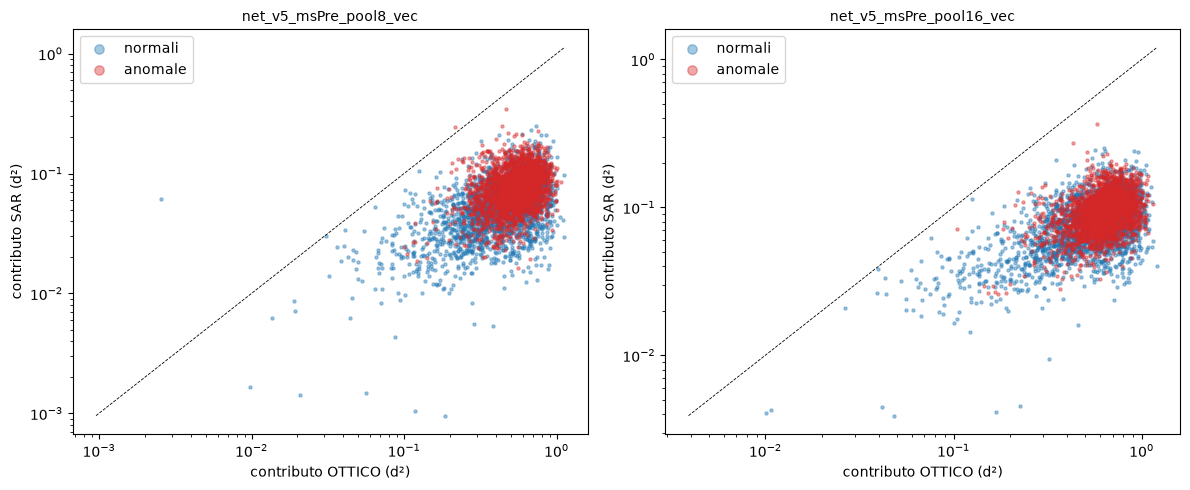

In [18]:
# è piu vicina la ka per ottico o sar

fig, axs = plt.subplots(1, len(dati), figsize=(6 * len(dati), 5), squeeze=False)
for ax, (ver, d) in zip(axs[0], dati.items()):
    (on, sn), (oa, sa) = d["parti_n"], d["parti_a"]
    ax.scatter(on, sn, s=5, alpha=.4, label="normali")
    ax.scatter(oa, sa, s=5, alpha=.4, label="anomale", color="tab:red")
    lim = [min(on.min(), sn.min(), oa.min(), sa.min()), max(on.max(), sn.max(), oa.max(), sa.max())]
    ax.plot(lim, lim, "k--", lw=.6)                          # sopra la diagonale: pesa più il SAR
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("contributo OTTICO (d²)"); ax.set_ylabel("contributo SAR (d²)")
    ax.set_title(ver, fontsize=10); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

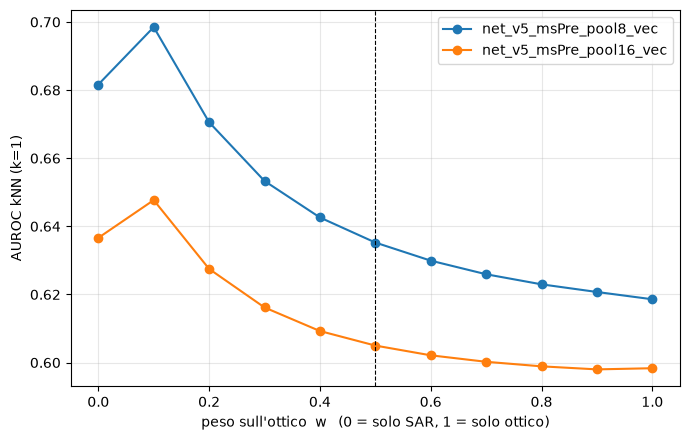

In [19]:
# auroc migliore a parità di percentuale di sar e ottico

fig, ax = plt.subplots(figsize=(7, 4.5))
for ver, d in dati.items():
    c = d["curva_w"]
    ax.plot(list(c), list(c.values()), marker="o", label=ver)
ax.axvline(.5, color="k", ls="--", lw=.8)
ax.set_xlabel("peso sull'ottico  w   (0 = solo SAR, 1 = solo ottico)")
ax.set_ylabel(f"AUROC kNN (k={K})"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**PCA LW SAR vs OPT vs CONC**

In [ ]:
from sklearn.decomposition import PCA

N_COMP = 1024              

dati_lw = {}
for ver, d in dati.items():
    Dq = d["Dq"]
    if Dq <= N_COMP:                          
        dati_lw[ver] = d
        continue

    pca = {}
    for m, sl in (("o", slice(0, Dq)), ("s", slice(Dq, None))):
        pca[m] = PCA(N_COMP, random_state=0).fit(d["Xf"][:, sl])          

    nuovo = {"Dq": N_COMP + 1}                 
    for g in ("Xf", "Xn", "Xa"):
        parti = []
        for m, sl in (("o", slice(0, Dq)), ("s", slice(Dq, None))):
            X = d[g][:, sl]
            P = pca[m].transform(X)
            res = ((X - pca[m].inverse_transform(P)) ** 2).sum(1, keepdims=True)   
            parti.append(np.concatenate([P, np.log1p(res)], axis=1))             
        nuovo[g] = np.concatenate(parti, axis=1).astype(np.float32)

    dati_lw[ver] = nuovo
    var = [pca[m].explained_variance_ratio_.sum() for m in ("o", "s")]
    print(f"{ver}: {2 * Dq} -> {2 * (N_COMP + 1)} dim | varianza tenuta OPT {var[0]:.0%}, SAR {var[1]:.0%}")

IndentationError: expected an indented block after 'for' statement on line 14 (2054431007.py, line 15)

In [28]:
for ver, d in dati.items():
    Dq = d["Dq"]
    for nome, sl in (("OPT", slice(0, Dq)), ("SAR", slice(Dq, None))):
        p = PCA(N_COMP, random_state=0).fit(d["Xf"][:, sl])
        res = lambda X: ((X - p.inverse_transform(p.transform(X))) ** 2).sum(1)   # quanto viene scartato
        print(f"{ver} {nome}: AUROC del residuo {auroc(res(d['Xn'][:, sl]), res(d['Xa'][:, sl])):.3f}")

net_v5_msPre_pool8_vec OPT: AUROC del residuo 0.643
net_v5_msPre_pool8_vec SAR: AUROC del residuo 0.717
net_v5_msPre_pool16_vec OPT: AUROC del residuo 0.748
net_v5_msPre_pool16_vec SAR: AUROC del residuo 0.865


In [ ]:
# pca lw

K = 1
MAX_FIT = 5000
BLOCCO = 500                                   # riduci se finisce la RAM

def auroc(sn, sa):
    return roc_auc_score(np.r_[np.zeros(len(sn)), np.ones(len(sa))], np.r_[sn, sa])

def prepara_lw(Xf):
    mu, sd = Xf.mean(0), Xf.std(0) + 1e-8
    Z = ((Xf - mu) / sd).astype(np.float64)
    alpha = ledoit_wolf_shrinkage(Z)
    lam, V = np.linalg.eigh(Z.T @ Z / len(Z))
    lam = (1 - alpha) * lam + alpha * lam.mean()
    return mu, sd, V / np.sqrt(lam), (V / lam) @ V.T

def knn_lw(Xt, Xf, prep, Dq=None, k=K, blocco=BLOCCO):
    mu, sd, W, P = prep
    Zt = (Xt - mu) / sd
    Zf = ((Xf - mu) / sd).astype(np.float64)
    Yf = Zf @ W; nYf = (Yf ** 2).sum(1)
    score, opt, sar, inc = [], [], [], []
    for i in range(0, len(Zt), blocco):
        Zb = Zt[i:i + blocco].astype(np.float64)
        Yb = Zb @ W
        d = np.clip((Yb ** 2).sum(1)[:, None] + nYf[None] - 2 * Yb @ Yf.T, 0, None)
        vic = np.argpartition(d, k - 1, axis=1)[:, :k]
        score.append(np.take_along_axis(d, vic, 1).mean(1))
        if Dq is not None:
            Delta = Zb[:, None, :] - Zf[vic]                          
            Do, Ds = Delta[..., :Dq], Delta[..., Dq:]
            opt.append(((Do @ P[:Dq, :Dq]) * Do).sum(-1).mean(1))      
            sar.append(((Ds @ P[Dq:, Dq:]) * Ds).sum(-1).mean(1))      
            inc.append(2 * ((Ds @ P[Dq:, :Dq]) * Do).sum(-1).mean(1))  
    score = np.concatenate(score)
    return (score, (np.concatenate(opt), np.concatenate(sar), np.concatenate(inc))) if Dq is not None else score

rng = np.random.default_rng(0)
for ver, d in dati_lw.items():
    Xf, Dq = d["Xf"], d["Dq"]
    if MAX_FIT and len(Xf) > MAX_FIT:
        Xf = Xf[rng.choice(len(Xf), MAX_FIT, replace=False)]
    if Xf.shape[1] > 4096:
        print(f"{ver}: {Xf.shape[1]} dimensioni, troppe per la lw, salto"); continue
    o, s = slice(0, Dq), slice(Dq, None)

    
    prep = prepara_lw(Xf)
    d["lw_score_n"], d["lw_parti_n"] = knn_lw(d["Xn"], Xf, prep, Dq)
    d["lw_score_a"], d["lw_parti_a"] = knn_lw(d["Xa"], Xf, prep, Dq)

    
    p_o, p_s = prepara_lw(Xf[:, o]), prepara_lw(Xf[:, s])
    so_n, so_a = knn_lw(d["Xn"][:, o], Xf[:, o], p_o), knn_lw(d["Xa"][:, o], Xf[:, o], p_o)
    ss_n, ss_a = knn_lw(d["Xn"][:, s], Xf[:, s], p_s), knn_lw(d["Xa"][:, s], Xf[:, s], p_s)
    d["lw_singole"] = {"solo SAR": (ss_n, ss_a), "solo OPT": (so_n, so_a)}

    def blocchi(X):                             
        mo, sdo, Wo, _ = p_o; ms, sds, Ws, _ = p_s
        return np.concatenate([((X[:, o] - mo) / sdo) @ Wo, ((X[:, s] - ms) / sds) @ Ws], axis=1).astype(np.float32)
    Bf = blocchi(Xf)
    ident = (np.zeros(Bf.shape[1]), np.ones(Bf.shape[1]), np.eye(Bf.shape[1]), None)   
    d["lw_singole"]["a blocchi"] = (knn_lw(blocchi(d["Xn"]), Bf, ident), knn_lw(blocchi(d["Xa"]), Bf, ident))
    print(f"{ver}: fatto")

net_v5_msPre_pool8_vec: fatto
net_v5_msPre_pool16_vec: 8192 dimensioni, troppe per la lw, salto


In [21]:
# risultati

riass_lw = {}
for ver, d in dati.items():
    if "lw_parti_n" not in d:
        continue
    (on, sn, inc_n), (oa, sa, inc_a) = d["lw_parti_n"], d["lw_parti_a"]
    tot_n, tot_a = d["lw_score_n"], d["lw_score_a"]
    sing = {nome: auroc(*v) for nome, v in d["lw_singole"].items()}
    riass_lw[ver] = {
        "AUROC concatenato": auroc(tot_n, tot_a),
        "AUROC parte OPT": auroc(on, oa),
        "AUROC parte SAR": auroc(sn, sa),
        "AUROC parte incrociata": auroc(inc_n, inc_a),
        "AUROC solo SAR": sing["solo SAR"],
        "AUROC solo OPT": sing["solo OPT"],
        "AUROC a blocchi": sing["a blocchi"],
        "quota OPT normali": (on / tot_n).mean(),
        "quota OPT anomale": (oa / tot_a).mean(),
        "quota SAR normali": (sn / tot_n).mean(),
        "quota SAR anomale": (sa / tot_a).mean(),
        "quota incrociata normali": (inc_n / tot_n).mean(),
        "quota incrociata anomale": (inc_a / tot_a).mean(),
        "guadagno vicini congiunti": sing["a blocchi"] - max(sing["solo SAR"], sing["solo OPT"]),
        "guadagno correlazione": auroc(tot_n, tot_a) - sing["a blocchi"],
    }
pd.DataFrame(riass_lw).round(3)

,net_v5_msPre_pool8_vec
AUROC concatenato,0.885
AUROC parte OPT,0.746
AUROC parte SAR,0.917
AUROC parte incrociata,0.487
AUROC solo SAR,0.922
AUROC solo OPT,0.748
AUROC a blocchi,0.880
quota OPT normali,0.416
quota OPT anomale,0.407
quota SAR normali,0.643


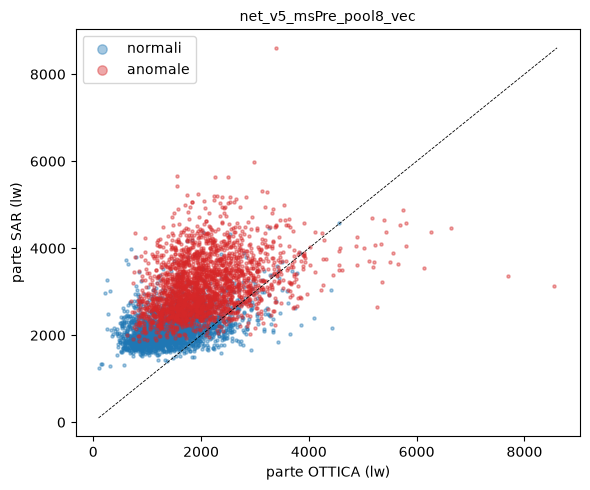

In [22]:
# scatter

vers = [v for v in dati if "lw_parti_n" in dati[v]]
fig, axs = plt.subplots(1, len(vers), figsize=(6 * len(vers), 5), squeeze=False)
for ax, ver in zip(axs[0], vers):
    d = dati[ver]
    (on, sn, _), (oa, sa, _) = d["lw_parti_n"], d["lw_parti_a"]
    ax.scatter(on, sn, s=5, alpha=.4, label="normali")
    ax.scatter(oa, sa, s=5, alpha=.4, label="anomale", color="tab:red")
    lim = [min(on.min(), sn.min(), oa.min(), sa.min()), max(on.max(), sn.max(), oa.max(), sa.max())]
    ax.plot(lim, lim, "k--", lw=.6)
    ax.set_xlabel("parte OTTICA (lw)"); ax.set_ylabel("parte SAR (lw)")
    ax.set_title(ver, fontsize=10); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

In [23]:
# calcolo per grafico sotto

PESI = np.round(np.linspace(0, 1, 11), 2)

rng = np.random.default_rng(0)
for ver, d in dati.items():
    if "lw_parti_n" not in d:
        continue
    Xf, Dq = d["Xf"], d["Dq"]
    if MAX_FIT and len(Xf) > MAX_FIT:
        Xf = Xf[rng.choice(len(Xf), MAX_FIT, replace=False)]   
    o, s = slice(0, Dq), slice(Dq, None)
    p_o, p_s = prepara_lw(Xf[:, o]), prepara_lw(Xf[:, s])     

    def sbianca(X, p):
        mu, sd, W, _ = p
        return (((X - mu) / sd) @ W).astype(np.float32)

    Yf = (sbianca(Xf[:, o], p_o), sbianca(Xf[:, s], p_s))
    Yn = (sbianca(d["Xn"][:, o], p_o), sbianca(d["Xn"][:, s], p_s))
    Ya = (sbianca(d["Xa"][:, o], p_o), sbianca(d["Xa"][:, s], p_s))
    curva = {}
    for w in PESI:
        
        pesa = lambda Y: np.concatenate([np.sqrt(w) * Y[0], np.sqrt(1 - w) * Y[1]], axis=1)
        F = pesa(Yf)
        I = (0, 1, np.eye(F.shape[1], dtype=np.float32), None)  
        curva[w] = auroc(knn_lw(pesa(Yn), F, I), knn_lw(pesa(Ya), F, I))
    d["lw_curva_w"] = curva
    w_best = max(curva, key=curva.get)
    print(f"{ver}: w migliore {w_best} (AUROC {curva[w_best]:.3f}) | lw completa {auroc(d['lw_score_n'], d['lw_score_a']):.3f}")

net_v5_msPre_pool8_vec: w migliore 0.0 (AUROC 0.922) | lw completa 0.885


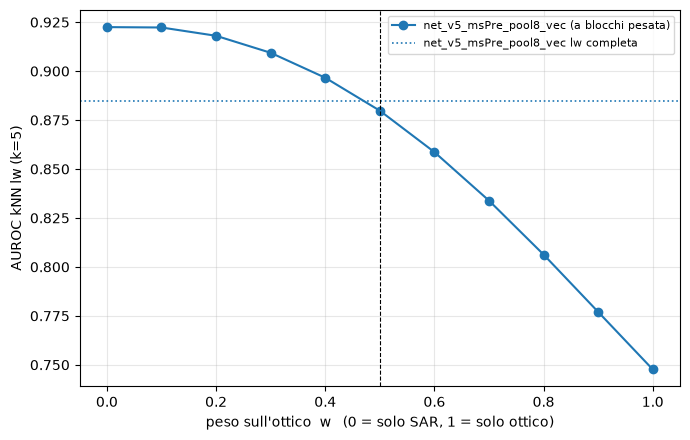

In [24]:
# grafico

fig, ax = plt.subplots(figsize=(7, 4.5))
for ver, d in dati.items():
    if "lw_curva_w" not in d:
        continue
    c = d["lw_curva_w"]
    linea, = ax.plot(list(c), list(c.values()), marker="o", label=f"{ver} (a blocchi pesata)")
    ax.axhline(auroc(d["lw_score_n"], d["lw_score_a"]), color=linea.get_color(), ls=":", lw=1.2,
               label=f"{ver} lw completa")
ax.axvline(.5, color="k", ls="--", lw=.8)
ax.set_xlabel("peso sull'ottico  w   (0 = solo SAR, 1 = solo ottico)")
ax.set_ylabel(f"AUROC kNN lw (k={K})"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [ ]:
# riassunto risultati

tutti = {"std": riass1, "coseno": riass2, "lw": riass_lw}

tab = pd.concat({dist: pd.DataFrame(r) for dist, r in tutti.items()}, axis=1)
tab.round(3)

In [ ]:
from sklearn.covariance import ledoit_wolf_shrinkage

MAX_FIT = 5000
TAGLI = [0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 4000]   # M = componenti grandi scartate

def curva_minori(Xf, Xn, Xa, tagli=TAGLI):
    """AUROC dello score 'distanza dalla media delle normali' usando solo le componenti dalla M+1 in poi + residuo."""
    mu, sd = Xf.mean(0), Xf.std(0) + 1e-8
    Zf = ((Xf - mu) / sd).astype(np.float64)
    c = Zf.mean(0)
    U, S, Vt = np.linalg.svd(Zf - c, full_matrices=False)       # tutte le componenti stimabili (≤ n_fit)
    lam = S ** 2 / (len(Zf) - 1)                                 # varianza di ogni componente
    alpha = ledoit_wolf_shrinkage(Zf)
    lam_s = (1 - alpha) * lam + alpha * lam.mean()               # shrinkage: evita di gonfiare le varianze minuscole
    out = {}
    for nome, X in (("n", Xn), ("a", Xa)):
        Z = ((X - mu) / sd).astype(np.float64) - c
        P = Z @ Vt.T                                             # coordinate su tutte le componenti
        res = (Z ** 2).sum(1) - (P ** 2).sum(1)                  # parte fuori da tutte le componenti stimabili
        contr = P ** 2 / lam_s                                   # contributo (sbiancato) di ogni componente
        coda = np.cumsum(contr[:, ::-1], axis=1)[:, ::-1]        # coda[:, M] = somma dalla componente M in poi
        out[nome] = (coda, res / (alpha * lam.mean()))           # residuo pesato come una direzione "solo shrinkage"
    curva = {}
    for M in tagli:
        if M >= len(lam):
            continue
        sn = out["n"][0][:, M] + out["n"][1]
        sa = out["a"][0][:, M] + out["a"][1]
        curva[M] = auroc(sn, sa)
    solo_res = auroc(out["n"][1], out["a"][1])
    return curva, solo_res, len(lam)

rng = np.random.default_rng(0)
minori = {}
for ver, d in dati.items():
    Xf, Dq = d["Xf"], d["Dq"]
    if MAX_FIT and len(Xf) > MAX_FIT:
        Xf = Xf[rng.choice(len(Xf), MAX_FIT, replace=False)]
    minori[ver] = {}
    for nome, sl in (("OPT", slice(0, Dq)), ("SAR", slice(Dq, None)), ("OPT+SAR", slice(None))):
        curva, solo_res, n_comp = curva_minori(Xf[:, sl], d["Xn"][:, sl], d["Xa"][:, sl])
        minori[ver][nome] = curva
        print(f"{ver} {nome}: {n_comp} componenti stimabili | solo residuo {solo_res:.3f} | "
              f"M migliore {max(curva, key=curva.get)} -> {max(curva.values()):.3f} (M=0: {curva[0]:.3f})")

fig, axs = plt.subplots(1, len(minori), figsize=(6 * len(minori), 4.5), squeeze=False)
for ax, (ver, cur) in zip(axs[0], minori.items()):
    for nome, c in cur.items():
        ax.plot(list(c), list(c.values()), marker="o", label=nome)
    ax.set_xscale("symlog", linthresh=1); ax.grid(alpha=.3)
    ax.set_xlabel("M = componenti più grandi scartate"); ax.set_ylabel("AUROC"); ax.set_title(ver, fontsize=10)
    ax.legend()
plt.tight_layout(); plt.show()

**PCA SPAZIO FEATURE**

In [ ]:

N_PC = 300                
MAX_FIT = 5000

rng = np.random.default_rng(0)
for ver, d in dati.items():
    Xf, Dq = d["Xf"], d["Dq"]
    if MAX_FIT and len(Xf) > MAX_FIT:
        Xf = Xf[rng.choice(len(Xf), MAX_FIT, replace=False)]
    mu, sd = Xf.mean(0), Xf.std(0) + 1e-8                     
    n_pc = min(N_PC, len(Xf) - 1, Xf.shape[1])
    pca = PCA(n_pc, svd_solver="randomized", random_state=0).fit((Xf - mu) / sd)

    Pn = pca.transform((d["Xn"] - mu) / sd)                    
    Pa = pca.transform((d["Xa"] - mu) / sd)
    _, auroc_pc = auroc_colonne(Pn, Pa)                       

    load = pca.components_                                    
    quota_opt = (load[:, :Dq] ** 2).sum(1)                     

    d["pca"] = {"var": pca.explained_variance_ratio_, "var_tot": pca.explained_variance_ratio_.sum(),
                "quota_opt": quota_opt, "auroc": auroc_pc, "Pn": Pn, "Pa": Pa}
    print(f"{ver}: {n_pc} componenti, varianza spiegata {d['pca']['var_tot']:.0%}")

In [ ]:
fig, axs = plt.subplots(3, len(dati), figsize=(6 * len(dati), 8), squeeze=False, sharex="col")
for j, (ver, d) in enumerate(dati.items()):
    p = d["pca"]; x = np.arange(1, len(p["var"]) + 1)
    axs[0, j].plot(x, p["var"]); axs[0, j].set_yscale("log")
    axs[0, j].set_ylabel("varianza spiegata"); axs[0, j].set_title(ver, fontsize=10)
    axs[1, j].bar(x, p["quota_opt"], width=1, color="tab:green")
    axs[1, j].axhline(.5, color="k", ls="--", lw=.6); axs[1, j].set_ylim(0, 1)
    axs[1, j].set_ylabel("quota OTTICO")
    axs[2, j].bar(x, p["auroc"], width=1, color="tab:red")
    axs[2, j].axhline(.6, color="k", ls="--", lw=.6); axs[2, j].set_ylim(.5, max(.75, p["auroc"].max() + .02))
    axs[2, j].set_ylabel("AUROC componente"); axs[2, j].set_xlabel("componente (1 = più varianza)")
    for ax in axs[:, j]:
        ax.set_xscale("log")
plt.tight_layout(); plt.show()

In [ ]:
riass3 = {}
for ver, d in dati.items():
    p = d["pca"]; n = len(p["var"]); cum = np.cumsum(p["var"]) / p["var"].sum()
    top = np.argsort(p["auroc"])[::-1][:10]                    # le 10 componenti più discriminanti
    primi = slice(0, max(1, n // 10)); ultimi = slice(n - max(1, n // 10), n)
    riass3[ver] = {
        "componenti calcolate": n,
        "varianza spiegata (tot)": p["var_tot"],
        "componenti per 90% (delle calcolate)": int(np.searchsorted(cum, .9) + 1),
        "AUROC max componente": p["auroc"].max(),
        "posizione componente migliore": int(np.argmax(p["auroc"]) + 1),
        "posizione mediana top-10 AUROC": float(np.median(top + 1)),
        "AUROC medio primo 10% componenti": p["auroc"][primi].mean(),
        "AUROC medio ultimo 10% componenti": p["auroc"][ultimi].mean(),
        "quota OTTICO primo 10% componenti": p["quota_opt"][primi].mean(),
        "quota OTTICO top-10 AUROC": p["quota_opt"][top].mean(),
    }
pd.DataFrame(riass3).round(3)

In [ ]:
fig, axs = plt.subplots(2, len(dati), figsize=(5.5 * len(dati), 10), squeeze=False)
for j, (ver, d) in enumerate(dati.items()):
    p = d["pca"]
    best = np.argsort(p["auroc"])[::-1][:2]                    # le due componenti più discriminanti
    for i, (c1, c2, tit) in enumerate(((0, 1, "più varianza"), (best[0], best[1], "più discriminanti"))):
        ax = axs[i, j]
        ax.scatter(p["Pn"][:, c1], p["Pn"][:, c2], s=4, alpha=.4, label="normali")
        ax.scatter(p["Pa"][:, c1], p["Pa"][:, c2], s=4, alpha=.4, label="anomale", color="tab:red")
        ax.set_xlabel(f"PC{c1 + 1}  (OPT {p['quota_opt'][c1]:.0%}, AUROC {p['auroc'][c1]:.2f})", fontsize=8)
        ax.set_ylabel(f"PC{c2 + 1}  (OPT {p['quota_opt'][c2]:.0%}, AUROC {p['auroc'][c2]:.2f})", fontsize=8)
        ax.set_title(f"{ver}\n{tit}", fontsize=9); ax.legend(markerscale=3, fontsize=7)
plt.tight_layout(); plt.show()

**CANCELLA CARTELLA**

In [ ]:
import shutil, glob

TUTTO = False
ESEGUI = False              

def dimensione(path):
    if os.path.isfile(path):
        return os.path.getsize(path)
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(path) for f in fs)

if TUTTO:
    bersagli = [CARTELLA] if os.path.exists(CARTELLA) else []
else:
    bersagli = [f"{CARTELLA}/{ver}/{PUNTO}" for ver in VERSIONI if os.path.exists(f"{CARTELLA}/{ver}/{PUNTO}")]
    bersagli += glob.glob(f"{CARTELLA}/_tmp_*.zip")

totale = 0
for b in bersagli:
    mb = dimensione(b) / 1e6; totale += mb
    print(f"{'cancello' if ESEGUI else 'da cancellare'}: {b}  ({mb:.0f} MB)")
    if ESEGUI:
        shutil.rmtree(b) if os.path.isdir(b) else os.remove(b)

if ESEGUI and not TUTTO:                      # rimuove le cartelle di versione rimaste vuote
    for ver in VERSIONI:
        d = f"{CARTELLA}/{ver}"
        if os.path.isdir(d) and all(f == "summary.json" for f in os.listdir(d)):
            shutil.rmtree(d)

print(f"{'liberati' if ESEGUI else 'liberabili'}: {totale:.0f} MB" if bersagli else "niente da cancellare")

cancello: ./vec/net_v5_msPre_pool8_vec/encoder_fine  (208 MB)
cancello: ./vec/net_v5_msPre_pool16_vec/encoder_fine  (831 MB)
liberati: 1040 MB


In [47]:
# libera anche la RAM occupata dagli embedding caricati (facoltativo)
for nome in ("dati", "top", "riassunto"):
    globals().pop(nome, None)
import gc; gc.collect()

88969